# Hito 2| Comparación de dos modelos para detectar EPP

Para optimización del tiempo, el hito 2 se dividirá en notebook diferentes que tocarán distintos puntos y entregables del proyecto.

Este busca comparar *dos modelos preentrenados de imágenes* en el mismo conjunto de prueba SH17.

- **YOLOv8n** = modelo pequeño ya entrenado en el Hito 2. Se reutiliza su `best.pt` sin entrenarlo otra vez.
- **YOLOv8s** = modelo algo más grande. Lo adaptaremos al mismo conjunto SH17.
- **Test** = fotografías reservadas exclusivamente para medir resultados. No se usan para entrenar.
- **Recall** = proporción de EPP presentes que el detector consigue encontrar.
- **mAP50-95** = medida global de precisión para detectar objetos y localizar sus cajas.

Por cierto, este notebook solamente lee archivos del Hito 1. Todos los resultados nuevos se guardan bajo `Examen_Hito2_EPP`. El Hito 1 no se modifica.

## Paso 0.1: Preparar Colab


Instalamos la misma versión de Ultralytics utilizada en la evaluación del Hito 2.

In [1]:
%pip -q install "ultralytics==8.4.213" "pyyaml"

## Paso 0.2: Comprobar datos, GPU y modelo ya entrenado

Este paso **no entrena nada**. Solo busca el modelo antiguo y las fotografías de SH17, y prepara una copia de la configuración del dataset en una carpeta nueva. Si falta algo, mostrará qué hay que corregir.

In [2]:
from pathlib import Path
from datetime import datetime, timezone
from google.colab import drive
import torch
import yaml

drive.mount('/content/drive')

RAIZ = Path('/content/drive/MyDrive/Examen_Hito2_EPP')
MODELO_N = (RAIZ / 'Entrenamientos_YOLO'
            / 'YOLOv8n_SH17_Hito2_640_B32_RAM_v1'
            / 'weights' / 'best.pt')

CANDIDATOS = [
    Path('/content/SH17_reducido'),
    RAIZ / 'Datasets' / 'SH17_reducido',
]

def contar_imagenes(carpeta):
    return sum(1 for ext in ('*.jpg', '*.jpeg', '*.png', '*.JPG', '*.JPEG', '*.PNG')
               for _ in carpeta.glob(ext)) if carpeta.is_dir() else 0

DATASET = None
for candidato in CANDIDATOS:
    cantidades = {s: contar_imagenes(candidato / 'images' / s)
                  for s in ('train', 'val', 'test')}
    print('Datos encontrados en:', candidato)
    print('  Imágenes:', cantidades)
    if all(cantidades[s] >= minimo for s, minimo in
           [('train', 1801), ('val', 810), ('test', 810)]):
        DATASET = candidato
        break

print('Modelo YOLOv8n existente:', 'OK' if MODELO_N.is_file() else 'FALTA')
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'NO DISPONIBLE')

LISTO = DATASET is not None and MODELO_N.is_file() and torch.cuda.is_available()

if LISTO:
    IDENTIFICADOR = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
    PREP = RAIZ / 'Evaluaciones' / f'Comparacion_Imagenes_Preparacion_{IDENTIFICADOR}'
    PREP.mkdir(parents=True, exist_ok=False)

    nombres = ['person','ear','ear-mufs','face','face-guard','face-mask',
               'foot','tool','glasses','gloves','helmet','hands','head',
               'medical-suit','shoes','safety-suit','safety-vest']
    configuracion = {
        'path': str(DATASET),
        'train': 'images/train', 'val': 'images/val', 'test': 'images/test',
        'nc': 17, 'names': {i: n for i, n in enumerate(nombres)}
    }
    DATA_YAML = PREP / 'sh17_comparacion.yaml'
    DATA_YAML.write_text(yaml.safe_dump(configuracion, sort_keys=False,
                                        allow_unicode=True), encoding='utf-8')
    print('\n✅ LISTO PARA COMENZAR')
    print('Configuración nueva:', DATA_YAML)
else:
    print('\n⚠️ TODAVÍA NO ESTÁ LISTO:')
    if DATASET is None:
        print('- No están disponibles las tres carpetas de imágenes SH17 completas.')
        print('  Revisa si el dataset sigue en Drive o si es necesario restaurarlo.')
    if not MODELO_N.is_file():
        print('- No encontré los pesos best.pt del YOLOv8n ya entrenado.')
    if not torch.cuda.is_available():
        print('- Activa una GPU T4 en el entorno de ejecución de Colab.')


Mounted at /content/drive
Datos encontrados en: /content/SH17_reducido
  Imágenes: {'train': 0, 'val': 0, 'test': 0}
Datos encontrados en: /content/drive/MyDrive/Examen_Hito2_EPP/Datasets/SH17_reducido
  Imágenes: {'train': 1801, 'val': 810, 'test': 810}
Modelo YOLOv8n existente: OK
GPU: Tesla T4

✅ LISTO PARA COMENZAR
Configuración nueva: /content/drive/MyDrive/Examen_Hito2_EPP/Evaluaciones/Comparacion_Imagenes_Preparacion_20261116T002644Z/sh17_comparacion.yaml


## 1. Preparación (sin entrenamiento)
Esta celda monta Drive, verifica que estén los archivos y descarga el segundo modelo.

In [4]:
%pip -q install "ultralytics==8.4.213" "huggingface_hub" "pandas" "matplotlib"


In [5]:
from pathlib import Path
from datetime import datetime, timezone
from google.colab import drive
from huggingface_hub import hf_hub_download
from ultralytics import YOLO
import torch
import hashlib

if not Path('/content/drive/MyDrive').exists():
    drive.mount('/content/drive')

RAIZ = Path('/content/drive/MyDrive/Examen_Hito2_EPP')
MODELO_N = (RAIZ / 'Entrenamientos_YOLO' /
    'YOLOv8n_SH17_Hito2_640_B32_RAM_v1' / 'weights' / 'best.pt')
assert MODELO_N.is_file(), f'No encuentro YOLOv8n: {MODELO_N}'

CANDIDATOS = [
    Path('/content/SH17_reducido'),
    RAIZ / 'Datasets' / 'SH17_reducido',
]
DATASET = next((p for p in CANDIDATOS if
    (p/'images'/'test').is_dir() and (p/'labels'/'test').is_dir()), None)
assert DATASET, 'Falta SH17_reducido con images/test y labels/test. No entrenes: recupera el respaldo de Drive.'

DIR_EXTERNO = RAIZ / 'Modelos_Externos' / 'Construction_Safety_YOLOv8s_v03'
DIR_EXTERNO.mkdir(parents=True, exist_ok=True)
MODELO_S = DIR_EXTERNO / 'buildvision-hazards-v0.3.pt'
if not MODELO_S.is_file():
    print('Descargando un YOLOv8s ya entrenado para EPP...')
    MODELO_S = Path(hf_hub_download(
        repo_id='constructelligence/construction-site-safety-hazards',
        filename='buildvision-hazards-v0.3.pt',
        local_dir=str(DIR_EXTERNO)
    ))

print('YOLOv8n existente:', MODELO_N)
print('YOLOv8s externo:', MODELO_S)
print('Dataset:', DATASET)
print('GPU disponible:', torch.cuda.is_available())
print('No se ha entrenado ningún modelo.')

Descargando un YOLOv8s ya entrenado para EPP...


buildvision-hazards-v0.3.pt: reconstructing file:   0%|          |  0.00B / 22.6MB            

buildvision-hazards-v0.3.pt: downloading bytes:           |  0.00B            

YOLOv8n existente: /content/drive/MyDrive/Examen_Hito2_EPP/Entrenamientos_YOLO/YOLOv8n_SH17_Hito2_640_B32_RAM_v1/weights/best.pt
YOLOv8s externo: /content/drive/MyDrive/Examen_Hito2_EPP/Modelos_Externos/Construction_Safety_YOLOv8s_v03/buildvision-hazards-v0.3.pt
Dataset: /content/drive/MyDrive/Examen_Hito2_EPP/Datasets/SH17_reducido
GPU disponible: True
No se ha entrenado ningún modelo.


## 2. Comparación de ambos modelos (sin entrenamiento)

Revisa **presencia de objetos por fotografía**. Para cada clase, el modelo indica si ve por lo menos un ejemplar. Para que la comparación sea justa, usamos **exactamente las mismas imágenes** y el mismo umbral de confianza (0,25).

> Las clases del modelo externo tienen nombres distintos. Por ejemplo, `hardhat` corresponde a `helmet`. Esta celda las hace equivalentes antes de comparar.

Se guardan los resultados automáticamente en **una carpeta nueva** de `Evaluaciones`. Puede demorar por procesar las fotografías, pero no hay épocas ni entrenamiento.

In [6]:
from collections import defaultdict
import pandas as pd
import numpy as np
import json
import time

CLASES = {
    'helmet': 10,
    'safety-vest': 16,
    'gloves': 9,
    'glasses': 8,
    'shoes': 14,
}
SINONIMOS = {
    'helmet': {'helmet','hardhat','hard hat'},
    'safety-vest': {'safety vest','safetyvest','vest','hi vis vest'},
    'gloves': {'gloves','glove'},
    'glasses': {'glasses','goggles','safety glasses','safety goggles'},
    'shoes': {'shoes','safety shoes','safety boots','boots'},
}

def normalizar(nombre):
    return ' '.join(str(nombre).lower().replace('-', ' ').replace('_', ' ').split())

def homologar(names):
    mapa = {}
    for idx, nombre in dict(names).items():
        etiqueta = normalizar(nombre)
        for clase, sinonimos in SINONIMOS.items():
            if etiqueta in sinonimos:
                mapa[int(idx)] = clase
    disponibles = set(mapa.values())
    if disponibles != set(CLASES):
        faltantes = set(CLASES) - disponibles
        raise ValueError(f'El modelo no reconoce estas clases: {faltantes}. Sus nombres: {names}')
    return mapa

imgs = sorted([p for p in (DATASET/'images'/'test').iterdir()
              if p.suffix.lower() in ('.jpg','.jpeg','.png','.bmp','.webp')])
assert len(imgs) == 810, f'Esperaba 810 fotos de test, encontré {len(imgs)}'

# Etiquetas SH17: 0=persona, 8=lentes, 9=guantes, 10=casco, 14=zapatos, 16=chaleco.
verdad = {}
for imagen in imgs:
    ruta_label = DATASET/'labels'/'test'/(imagen.stem+'.txt')
    ids = set()
    if ruta_label.exists():
        for linea in ruta_label.read_text(encoding='utf-8').splitlines():
            partes = linea.strip().split()
            if partes:
                ids.add(int(float(partes[0])))
    verdad[imagen.stem] = {c: int(id_sh17 in ids) for c, id_sh17 in CLASES.items()}

carpeta = RAIZ / 'Evaluaciones' / (
    'Comparacion_PREENTRENADOS_SIN_ENTRENAR_' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ'))
carpeta.mkdir(parents=True, exist_ok=False)

dispositivo = 0 if torch.cuda.is_available() else 'cpu'
registros = []
velocidades = []

for nombre_modelo, ruta_pesos in [('YOLOv8n_SH17', MODELO_N), ('YOLOv8s_externo', MODELO_S)]:
    print(f'Evaluando {nombre_modelo}...')
    detector = YOLO(str(ruta_pesos))
    mapa = homologar(detector.names)
    encontrados = set()
    t0 = time.perf_counter()
    generador = detector.predict(
        source=str(DATASET/'images'/'test'),
        conf=0.25, imgsz=640, device=dispositivo,
        stream=True, verbose=False, save=False
    )
    tiempos_inferencia = []
    for salida in generador:
        stem = Path(salida.path).stem
        if stem not in verdad:
            continue
        assert stem not in encontrados, f'Fotografía repetida: {stem}'
        encontrados.add(stem)
        identificadas = {mapa[int(i)] for i in salida.boxes.cls.tolist()
                         if int(i) in mapa}
        tiempos_inferencia.append(float(salida.speed.get('inference', 0)))
        for clase in CLASES:
            registros.append({
                'modelo': nombre_modelo, 'imagen': stem,
                'epp': clase,
                'real_anotado': verdad[stem][clase],
                'detectado': int(clase in identificadas),
            })
    assert len(encontrados) == len(imgs), (
        f'{nombre_modelo}: se evaluaron {len(encontrados)} de {len(imgs)} imágenes')
    velocidades.append({
        'modelo': nombre_modelo,
        'segundos_totales': round(time.perf_counter()-t0,2),
        'ms_inferencia_promedio': round(float(np.mean(tiempos_inferencia)),2),
    })

tabla = pd.DataFrame(registros)
filas = []
for (nombre, clase), g in tabla.groupby(['modelo','epp'], sort=True):
    real = g['real_anotado'].to_numpy(dtype=int)
    pred = g['detectado'].to_numpy(dtype=int)
    tp = int(((real==1)&(pred==1)).sum())
    fp = int(((real==0)&(pred==1)).sum())
    fn = int(((real==1)&(pred==0)).sum())
    tn = int(((real==0)&(pred==0)).sum())
    precision = tp/(tp+fp) if tp+fp else 0.0
    recall = tp/(tp+fn) if tp+fn else 0.0
    f1 = 2*precision*recall/(precision+recall) if precision+recall else 0.0
    filas.append({
        'modelo':nombre, 'epp':clase, 'positivos_reales':tp+fn,
        'precision':round(precision,4), 'recall':round(recall,4),
        'f1':round(f1,4), 'TP':tp, 'FP':fp, 'FN':fn, 'TN':tn,
    })
metricas = pd.DataFrame(filas)
resumen = metricas.groupby('modelo')[['precision','recall','f1']].mean().round(4)
resumen = resumen.rename(columns={
    'precision':'precision_macro', 'recall':'recall_macro', 'f1':'f1_macro'})

tabla.to_csv(carpeta/'predicciones_por_imagen_y_epp.csv',index=False)
metricas.to_csv(carpeta/'metricas_por_epp.csv',index=False)
resumen.to_csv(carpeta/'comparacion_resumen.csv')
pd.DataFrame(velocidades).to_csv(carpeta/'tiempos.csv',index=False)

metadata = {
    'descripcion':'Comparación sin entrenamiento, presencia de EPP por imagen en test SH17',
    'imagenes_test':len(imgs), 'umbral_confianza':0.25, 'resolucion':640,
    'modelo_interno':str(MODELO_N), 'modelo_externo':str(MODELO_S),
    'fuente_externa':'https://huggingface.co/constructelligence/construction-site-safety-hazards',
    'advertencias':[
        'Comparación de presencia por imagen, NO de mAP ni cajas individuales.',
        'La procedencia externa de datos de entrenamiento no permite garantizar cero solapamiento con SH17.',
        'Las anotaciones SH17 pueden ser incompletas; ausencia de etiqueta no prueba ausencia real.',
        'Los modelos no fueron entrenados con igual dataset ni hiperparámetros.',
        'No constituye evidencia de cumplimiento efectivo de EPP por trabajador.'
    ]
}
(carpeta/'metodologia_y_limitaciones.json').write_text(
    json.dumps(metadata,ensure_ascii=False,indent=2),encoding='utf-8')
print('\nRESULTADOS PROMEDIO (en las mismas 810 imágenes):')
print(resumen.to_string())
print('\nRESULTADOS POR EPP:')
print(metricas.to_string(index=False))
print('\nTodo guardado en:',carpeta)

Evaluando YOLOv8n_SH17...
Evaluando YOLOv8s_externo...

RESULTADOS PROMEDIO (en las mismas 810 imágenes):
                 precision_macro  recall_macro  f1_macro
modelo                                                  
YOLOv8n_SH17              0.6219        0.6779    0.6441
YOLOv8s_externo           0.2230        0.2597    0.1388

RESULTADOS POR EPP:
         modelo         epp  positivos_reales  precision  recall     f1  TP  FP  FN  TN
   YOLOv8n_SH17     glasses               161     0.5920  0.6398 0.6149 103  71  58 578
   YOLOv8n_SH17      gloves               127     0.5923  0.6063 0.5992  77  53  50 630
   YOLOv8n_SH17      helmet                46     0.6327  0.6739 0.6526  31  18  15 746
   YOLOv8n_SH17 safety-vest                22     0.4412  0.6818 0.5357  15  19   7 769
   YOLOv8n_SH17       shoes               160     0.8514  0.7875 0.8182 126  22  34 628
YOLOv8s_externo     glasses               161     0.0000  0.0000 0.0000   0   0 161 649
YOLOv8s_externo      gloves  

## 3. Cómo interpretar el resultado

- **F1-macro:** promedio del F1 de los cinco EPP. Más alto es mejor, pero no prueba seguridad operativa.
- **Recall:** de los EPP etiquetados, cuántos encontró el modelo. Más alto es mejor en seguridad.
- **FP (falsos positivos):** indicó presencia cuando no había anotación de ese EPP.
- **FN (falsos negativos):** no encontró un EPP que sí estaba anotado.
- **Tiempo:** comparar el coste de procesar las mismas imágenes.



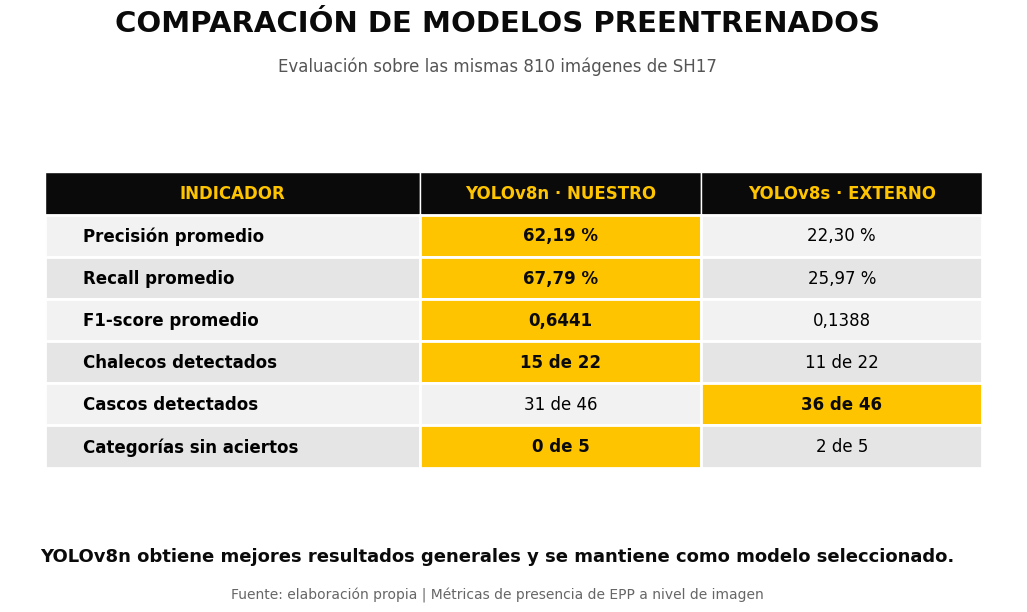

Tabla guardada en: /content/drive/MyDrive/Examen_Hito2_EPP/Evaluaciones/Tablas_Presentacion/comparacion_YOLOv8n_vs_YOLOv8s.png


In [7]:

import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display, Image

# ==========================================
# TABLA COMPARATIVA - HITO 2
# ==========================================

indicadores = [
    "Precisión promedio",
    "Recall promedio",
    "F1-score promedio",
    "Chalecos detectados",
    "Cascos detectados",
    "Categorías sin aciertos"
]

yolov8n = [
    "62,19 %",
    "67,79 %",
    "0,6441",
    "15 de 22",
    "31 de 46",
    "0 de 5"
]

yolov8s = [
    "22,30 %",
    "25,97 %",
    "0,1388",
    "11 de 22",
    "36 de 46",
    "2 de 5"
]

# Colores de la presentación
NEGRO = "#0A0A0A"
AMARILLO = "#FFC400"
BLANCO = "#FFFFFF"
GRIS = "#E8E8E8"

fig, ax = plt.subplots(figsize=(13, 6.5))
fig.patch.set_facecolor(BLANCO)
ax.axis("off")

fig.text(
    0.5, 0.94,
    "COMPARACIÓN DE MODELOS PREENTRENADOS",
    ha="center", va="center",
    fontsize=21, fontweight="bold",
    color=NEGRO
)

fig.text(
    0.5, 0.875,
    "Evaluación sobre las mismas 810 imágenes de SH17",
    ha="center", va="center",
    fontsize=12, color="#555555"
)

filas = [
    [indicadores[i], yolov8n[i], yolov8s[i]]
    for i in range(len(indicadores))
]

tabla = ax.table(
    cellText=filas,
    colLabels=[
        "INDICADOR",
        "YOLOv8n · NUESTRO",
        "YOLOv8s · EXTERNO"
    ],
    colWidths=[0.40, 0.30, 0.30],
    cellLoc="center",
    bbox=[0.035, 0.19, 0.93, 0.59]
)

tabla.auto_set_font_size(False)
tabla.set_fontsize(12)

# Encabezados
for j in range(3):
    celda = tabla[0, j]
    celda.set_facecolor(NEGRO)
    celda.get_text().set_color(AMARILLO)
    celda.get_text().set_weight("bold")
    celda.set_edgecolor(BLANCO)

# Cuerpo
for i in range(1, 7):
    for j in range(3):
        celda = tabla[i, j]
        celda.set_edgecolor(BLANCO)
        celda.set_linewidth(2)
        celda.set_facecolor(
            "#F2F2F2" if i % 2 else "#E5E5E5"
        )

        if j == 0:
            celda.get_text().set_weight("bold")
            celda.get_text().set_ha("left")

# Destacar el ganador de cada fila
# Índice 1: YOLOv8n
# Índice 2: YOLOv8s (solo cascos)
for i in range(1, 7):
    ganador = 2 if i == 5 else 1
    celda = tabla[i, ganador]
    celda.set_facecolor(AMARILLO)
    celda.get_text().set_color(NEGRO)
    celda.get_text().set_weight("bold")

# Mensaje final
fig.text(
    0.5, 0.12,
    "YOLOv8n obtiene mejores resultados generales "
    "y se mantiene como modelo seleccionado.",
    ha="center", va="center",
    fontsize=13, fontweight="bold",
    color=NEGRO
)

fig.text(
    0.5, 0.055,
    "Fuente: elaboración propia | "
    "Métricas de presencia de EPP a nivel de imagen",
    ha="center", fontsize=10,
    color="#666666"
)

# Guardar sin sobrescribir archivos previos
carpeta = Path(
    "/content/drive/MyDrive/Examen_Hito2_EPP/"
    "Evaluaciones/Tablas_Presentacion"
)
carpeta.mkdir(parents=True, exist_ok=True)

base = carpeta / "comparacion_YOLOv8n_vs_YOLOv8s.png"
salida = base
numero = 2

while salida.exists():
    salida = carpeta / (
        f"comparacion_YOLOv8n_vs_YOLOv8s_v{numero}.png"
    )
    numero += 1

plt.savefig(
    salida,
    dpi=300,
    bbox_inches="tight",
    facecolor=BLANCO
)

plt.show()
print("Tabla guardada en:", salida)


La evaluación de ambos modelos sobre las mismas 810 imágenes demuestra un mejor desempeño general de YOLOv8n, que alcanzó un F1-score promedio de 0,6441 frente al 0,1388 obtenido por YOLOv8s. Nuestro modelo también presentó mayor precisión y recall promedio, destacando especialmente en la detección de guantes, lentes y zapatos de seguridad.

Aunque YOLOv8s obtuvo un mayor recall en la detección de cascos, generó considerablemente más falsos positivos, lo que limita su confiabilidad. Estos resultados respaldan la elección de YOLOv8n para el sistema desarrollado, considerando que fue adaptado específicamente al conjunto SH17, mientras que el modelo externo no recibió ese ajuste.

No obstante, los resultados corresponden a la detección de presencia de EPP a nivel de imagen y no garantizan su correcta utilización por cada trabajador. Por ello, el sistema debe mantener mecanismos de revisión humana y evitar interpretar automáticamente un elemento no detectado como un incumplimiento confirmado.

---
# **RAG para recomendaciones de seguridad (Hito 2)**

**RAG:** técnica para encontrar fragmentos útiles de documentos y adjuntarlos a la pregunta que recibirá el LLM (Gemini).

**Transformer:** modelo que interpreta similitud de significado entre textos.

**TF-IDF:** comparación básica de coincidencia de palabras. Aquí todavía no enviamos nada a Gemini ni n8n: preparamos el contexto en JSON.


### 1. Creación de la biblioteca de procedimientos de seguridad

**Objetivo:** construir una biblioteca estructurada de procedimientos de seguridad que sirva como fuente de información para el sistema RAG.

En esta etapa se preparan **7 procedimientos de seguridad**, cada uno identificado mediante un código único, una zona de aplicación y un título. Esta organización permitirá localizar y referenciar los documentos relevantes cuando el sistema necesite generar recomendaciones a partir de las detecciones de EPP.

**El código realiza las siguientes operaciones:**

1. Conecta Google Drive para acceder a los archivos del proyecto.
2. Prepara una carpeta de trabajo independiente para el Hito 2, evitando modificar los archivos de etapas anteriores.
3. Organiza los procedimientos mediante identificadores únicos (`SIM-PROC-01` a `SIM-PROC-07`).
4. Muestra una tabla de verificación con los procedimientos cargados y sus respectivas zonas.

**Resultado esperado:** una biblioteca de 7 procedimientos organizados y disponibles para implementar posteriormente la recuperación de información mediante TF-IDF o modelos Transformer.

**Nota:** esta etapa no entrena modelos ni genera recomendaciones. Su función es preparar la información documental que utilizará el sistema RAG.

In [8]:
# 6.1 - Preparar documentos para RAG (NO entrena YOLO)
from pathlib import Path
from datetime import datetime, timezone
import json
import pandas as pd
from IPython.display import display
from google.colab import drive

if not Path('/content/drive/MyDrive').exists():
    drive.mount('/content/drive')

RAG_RAIZ = Path('/content/drive/MyDrive/Examen_Hito2_EPP')
RAG_SALIDA = RAG_RAIZ / 'Textos_NLP' / 'RAG_Procedimientos' / datetime.now(timezone.utc).strftime('%Y%m%d_%H%M%S_%f')
RAG_SALIDA.mkdir(parents=True, exist_ok=False)

# Estos textos provienen de los 7 procedimientos SIMULADOS del dataset v2.
# No se deben presentar como normas legales ni como protocolos profesionales validados.
RAG_DOCUMENTOS = pd.DataFrame([{'procedimiento_id': 'SIM-PROC-01', 'zona_id': 'zona_1', 'titulo': 'Control visual de casco y chaleco', 'texto': 'Al inicio de cada turno, registrar a las personas presentes y revisar visualmente casco y chaleco. La detección automática es apoyo y no acredita ajuste correcto ni certificación del EPP.', 'fuente_datos': 'SIMULADO', 'validado_profesionalmente': False}, {'procedimiento_id': 'SIM-PROC-02', 'zona_id': 'zona_2', 'titulo': 'Control visual de manos, pies y ojos', 'texto': 'Antes de iniciar actividades, verificar los requisitos específicos de calzado, guantes y protección ocular de acuerdo con la matriz de riesgos de la instalación.', 'fuente_datos': 'SIMULADO', 'validado_profesionalmente': False}, {'procedimiento_id': 'SIM-PROC-03', 'zona_id': 'ambas', 'titulo': 'Tratamiento de elemento no confirmado', 'texto': 'Cuando un EPP aparezca como no confirmado por el detector, solicitar verificación presencial. No registrar ausencia física ni infracción sin comprobación humana.', 'fuente_datos': 'SIMULADO', 'validado_profesionalmente': False}, {'procedimiento_id': 'SIM-PROC-04', 'zona_id': 'ambas', 'titulo': 'Manejo de inspección sin personas detectadas', 'texto': 'Si no se reconocen personas evaluables, clasificar el análisis como pendiente. Comprobar calidad de imagen y repetir captura cuando corresponda.', 'fuente_datos': 'SIMULADO', 'validado_profesionalmente': False}, {'procedimiento_id': 'SIM-PROC-05', 'zona_id': 'ambas', 'titulo': 'Registro y trazabilidad', 'texto': 'Guardar fecha, zona, turno, identificador de inspección, resultados de detección y decisión del supervisor. Separar información simulada de registros reales.', 'fuente_datos': 'SIMULADO', 'validado_profesionalmente': False}, {'procedimiento_id': 'SIM-PROC-06', 'zona_id': 'ambas', 'titulo': 'Condiciones de tránsito y visibilidad', 'texto': 'Ante cruces con vehículos y trabajadores, revisar segregación, señales y equipamiento requerido por la evaluación de riesgos del lugar.', 'fuente_datos': 'SIMULADO', 'validado_profesionalmente': False}, {'procedimiento_id': 'SIM-PROC-07', 'zona_id': 'ambas', 'titulo': 'Control de superficies y herramientas', 'texto': 'Revisar superficies de tránsito y medidas preventivas frente al contacto con objetos o equipos antes de asignar una prioridad de intervención.', 'fuente_datos': 'SIMULADO', 'validado_profesionalmente': False}])
RAG_DOCUMENTOS['contenido'] = RAG_DOCUMENTOS['titulo'] + '. ' + RAG_DOCUMENTOS['texto']
assert RAG_DOCUMENTOS['procedimiento_id'].is_unique
assert set(RAG_DOCUMENTOS['zona_id']) <= {'zona_1','zona_2','ambas'}
RAG_DOCUMENTOS.drop(columns='contenido').to_csv(RAG_SALIDA / 'procedimientos_referencia.csv', index=False)
print('Documentos cargados:', len(RAG_DOCUMENTOS))
print('Carpeta nueva:', RAG_SALIDA)
display(RAG_DOCUMENTOS[['procedimiento_id','zona_id','titulo']])

Documentos cargados: 7
Carpeta nueva: /content/drive/MyDrive/Examen_Hito2_EPP/Textos_NLP/RAG_Procedimientos/20261116_014357_509772


,procedimiento_id,zona_id,titulo
0,SIM-PROC-01,zona_1,Control visual de casco y chaleco
1,SIM-PROC-02,zona_2,"Control visual de manos, pies y ojos"
2,SIM-PROC-03,ambas,Tratamiento de elemento no confirmado
3,SIM-PROC-04,ambas,Manejo de inspección sin personas detectadas
4,SIM-PROC-05,ambas,Registro y trazabilidad
5,SIM-PROC-06,ambas,Condiciones de tránsito y visibilidad
6,SIM-PROC-07,ambas,Control de superficies y herramientas


### 2. Implementación del buscador baseline mediante TF-IDF

**Objetivo:** implementar un método inicial de recuperación de procedimientos de seguridad basado en similitud textual, que sirva como referencia para evaluar posteriormente un modelo Transformer.

Se utiliza **TF-IDF (Term Frequency–Inverse Document Frequency)** para representar numéricamente los documentos según la importancia de sus palabras. Posteriormente, mediante la **similitud coseno**, se identifican los procedimientos con mayor coincidencia respecto de una consulta.

**El código realiza las siguientes operaciones:**

1. Vectoriza el contenido de los procedimientos utilizando TF-IDF.
2. Filtra los documentos según la zona de aplicación, incluyendo los procedimientos generales.
3. Calcula la similitud entre la consulta y los documentos disponibles.
4. Selecciona los tres procedimientos con mayor puntuación de similitud.

**Prueba de funcionamiento:** se utiliza la consulta *"El chaleco no se detecta, ¿qué hacer?"*, correspondiente a `zona_1`.

**Resultado:** el buscador devuelve los procedimientos `SIM-PROC-04`, `SIM-PROC-01` y `SIM-PROC-03`, ordenados según sus puntuaciones de similitud textual.

**Interpretación:** los resultados confirman que el buscador permite recuperar y ordenar procedimientos relacionados con los términos de una consulta. Sin embargo, al basarse principalmente en coincidencias de palabras, puede priorizar documentos que no sean los más adecuados desde el punto de vista del contexto de seguridad.

Este baseline permitirá comparar posteriormente los resultados con un modelo Transformer, orientado a identificar similitudes semánticas entre consultas y procedimientos.

In [9]:
# 6.2 - Baseline: buscar documentos por coincidencia de palabras (TF-IDF)
# TF-IDF es un método simple para calcular similitud entre textos según palabras.
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

RAG_TFIDF = TfidfVectorizer(strip_accents='unicode', ngram_range=(1, 2))
RAG_MATRIZ_TFIDF = RAG_TFIDF.fit_transform(RAG_DOCUMENTOS['contenido'].tolist())

def rag_indices_permitidos(zona):
    if zona not in ('zona_1', 'zona_2', 'ambas'):
        raise ValueError('La zona debe ser zona_1, zona_2 o ambas')
    # Procedimientos generales ('ambas') se aplican a las dos zonas.
    if zona == 'ambas':
        return np.arange(len(RAG_DOCUMENTOS))
    return np.flatnonzero(RAG_DOCUMENTOS['zona_id'].isin([zona, 'ambas']).to_numpy())

def rag_buscar_tfidf(pregunta, zona, k=3):
    idx = rag_indices_permitidos(zona)
    q = RAG_TFIDF.transform([str(pregunta)])
    puntuaciones = cosine_similarity(q, RAG_MATRIZ_TFIDF[idx]).ravel()
    orden = np.argsort(-puntuaciones)[:k]
    return [(int(idx[j]), float(puntuaciones[j])) for j in orden]

print('Prueba del buscador simple:')
print([(RAG_DOCUMENTOS.iloc[i]['procedimiento_id'], round(p, 3))
       for i, p in rag_buscar_tfidf('El chaleco no se detecta, ¿qué hacer?', 'zona_1')])

Prueba del buscador simple:
[('SIM-PROC-04', 0.23), ('SIM-PROC-01', 0.158), ('SIM-PROC-03', 0.145)]


**Resultado:** el buscador devuelve los procedimientos `SIM-PROC-04`, `SIM-PROC-01` y `SIM-PROC-03`, ordenados según sus puntuaciones de similitud textual.

**Interpretación:** los resultados confirman que el buscador permite recuperar y ordenar procedimientos relacionados con los términos de una consulta. Sin embargo, al basarse principalmente en coincidencias de palabras, puede priorizar documentos que no sean los más adecuados desde el punto de vista del contexto de seguridad.

---

### 3. Implementación de búsqueda semántica mediante Transformer

**Objetivo:** implementar un método de recuperación de procedimientos basado en similitud semántica, que permita identificar documentos relevantes considerando el significado de las consultas y no únicamente la coincidencia de palabras.

Se utiliza el modelo preentrenado **`paraphrase-multilingual-MiniLM-L12-v2`**, de la biblioteca `sentence-transformers`, para transformar los procedimientos en *embeddings* (representaciones numéricas de su significado). Posteriormente, se calcula la similitud coseno entre estos vectores y la consulta ingresada.

**El código realiza las siguientes operaciones:**

1. Instala la biblioteca `sentence-transformers` y carga el modelo Transformer multilingüe.
2. Genera embeddings normalizados para los 7 procedimientos de seguridad.
3. Convierte la consulta en un embedding utilizando el mismo modelo.
4. Filtra los documentos según la zona de aplicación.
5. Calcula la similitud semántica y recupera los tres procedimientos con mayor puntuación.

**Prueba de funcionamiento:** se utiliza la consulta *"No está claro si lleva chaleco, ¿cómo proceder?"*, correspondiente a `zona_1`.


In [10]:
# 6.3 - Transformer: buscar documentos por significado, aunque cambien las palabras
# Embedding = lista de números que representa el significado aproximado de un texto.

%pip -q install sentence-transformers

from sentence_transformers import SentenceTransformer

RAG_NOMBRE_MODELO = 'sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2'
RAG_MODELO = SentenceTransformer(RAG_NOMBRE_MODELO, device='cpu')
RAG_EMBEDDINGS = RAG_MODELO.encode(
    RAG_DOCUMENTOS['contenido'].tolist(),
    normalize_embeddings=True,
    show_progress_bar=False
)

def rag_buscar_transformer(pregunta, zona, k=3):
    idx = rag_indices_permitidos(zona)
    q = RAG_MODELO.encode([str(pregunta)], normalize_embeddings=True, show_progress_bar=False)[0]
    puntuaciones = RAG_EMBEDDINGS[idx] @ q
    orden = np.argsort(-puntuaciones)[:k]
    return [(int(idx[j]), float(puntuaciones[j])) for j in orden]

print('Prueba del Transformer:')
print([(RAG_DOCUMENTOS.iloc[i]['procedimiento_id'], round(p, 3))
       for i, p in rag_buscar_transformer('No está claro si lleva chaleco, ¿cómo proceder?', 'zona_1')])

modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/645 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  471MB            

... (4 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Prueba del Transformer:
[('SIM-PROC-01', 0.211), ('SIM-PROC-03', 0.174), ('SIM-PROC-07', 0.153)]



**Resultado:** el buscador devuelve los procedimientos `SIM-PROC-01`, `SIM-PROC-03` y `SIM-PROC-07`, ordenados según sus puntuaciones de similitud semántica.

**Interpretación:** el modelo prioriza procedimientos relacionados con la consulta, destacando el control visual de casco y chaleco y el tratamiento de elementos no confirmados. Esto muestra la capacidad del método para identificar relaciones semánticas entre los textos.

Este enfoque complementa el baseline TF-IDF y permitirá evaluar posteriormente si la recuperación basada en significado ofrece mejores resultados para el sistema RAG de recomendaciones de seguridad.

---


### 6.4. Evaluación y comparación de métodos de recuperación

**Objetivo:** comparar el desempeño de los buscadores TF-IDF y Transformer mediante un conjunto común de preguntas, para identificar cuál recupera con mayor precisión los procedimientos de seguridad esperados.

Se utilizan **8 preguntas de evaluación**, cada una asociada a una zona y a un procedimiento considerado como respuesta correcta. Ambos métodos se evalúan utilizando las mismas consultas y recuperando los tres documentos con mayor similitud.

**El código realiza las siguientes operaciones:**

1. Define las 8 preguntas de prueba y sus respectivos procedimientos esperados.
2. Ejecuta ambos métodos de búsqueda utilizando las mismas consultas.
3. Calcula dos métricas de recuperación:
   - **Hit@1:** porcentaje de consultas donde el procedimiento esperado aparece en primer lugar.
   - **Hit@3:** porcentaje de consultas donde el procedimiento esperado aparece entre los tres primeros resultados.
4. Genera una tabla comparativa y guarda los resultados en archivos CSV para su posterior análisis.


In [11]:
# 6.4 - Comparar ambos métodos con LAS MISMAS 8 preguntas
# Hit@1 = porcentaje de preguntas cuyo documento esperado salió primero.
# Hit@3 = porcentaje de preguntas cuyo documento esperado quedó entre los 3 primeros.
RAG_PREGUNTAS = [
    {'pregunta':'¿Qué se revisa antes del turno en la primera zona?', 'zona':'zona_1','esperado':'SIM-PROC-01'},
    {'pregunta':'¿Qué protección se exige para pies, manos y ojos?', 'zona':'zona_2','esperado':'SIM-PROC-02'},
    {'pregunta':'El detector no confirma un chaleco; ¿se debe sancionar?', 'zona':'zona_1','esperado':'SIM-PROC-03'},
    {'pregunta':'La foto no permite identificar trabajadores; ¿qué hacemos?', 'zona':'ambas','esperado':'SIM-PROC-04'},
    {'pregunta':'¿Qué información hay que registrar después de inspeccionar?', 'zona':'ambas','esperado':'SIM-PROC-05'},
    {'pregunta':'Hay vehículos transitando junto a personas; ¿qué prevención aplicar?', 'zona':'ambas','esperado':'SIM-PROC-06'},
    {'pregunta':'¿Qué revisar cuando hay herramientas y problemas en el suelo?', 'zona':'ambas','esperado':'SIM-PROC-07'},
    {'pregunta':'Una protección no fue reconocida; ¿puedo afirmar su ausencia?', 'zona':'ambas','esperado':'SIM-PROC-03'},
]

RAG_RESULTADOS = []
for caso in RAG_PREGUNTAS:
    for nombre, funcion in [('TF-IDF', rag_buscar_tfidf), ('Transformer', rag_buscar_transformer)]:
        top = funcion(caso['pregunta'], caso['zona'], k=3)
        ids = [RAG_DOCUMENTOS.iloc[i]['procedimiento_id'] for i, p in top]
        RAG_RESULTADOS.append({
            'metodo':nombre,'zona':caso['zona'],'pregunta':caso['pregunta'],
            'documento_esperado':caso['esperado'], 'documento_top1':ids[0],
            'hit_1':int(ids[0]==caso['esperado']),
            'hit_3':int(caso['esperado'] in ids),
            'top_3':' | '.join(ids),
        })
RAG_TABLA = pd.DataFrame(RAG_RESULTADOS)
RAG_RESUMEN = RAG_TABLA.groupby('metodo', as_index=False)[['hit_1','hit_3']].mean()
RAG_TABLA.to_csv(RAG_SALIDA/'evaluacion_preguntas.csv',index=False)
RAG_RESUMEN.to_csv(RAG_SALIDA/'comparacion_metodos.csv',index=False)
print('Resultados (1.0 significa 100% de las preguntas de demostración):')
display(RAG_RESUMEN)
print('Nota: estas 8 preguntas se redactaron a partir de 7 procedimientos simulados. No es evaluación en campo.')

Resultados (1.0 significa 100% de las preguntas de demostración):


,metodo,hit_1,hit_3
0,TF-IDF,0.625,0.875
1,Transformer,0.750,1.000


Nota: estas 8 preguntas se redactaron a partir de 7 procedimientos simulados. No es evaluación en campo.



**Resultados obtenidos:**

| Método | Hit@1 | Hit@3 |
|---|---|---|
| TF-IDF | 62,5% | 87,5% |
| Transformer | 75,0% | 100,0% |

**Interpretación:** el Transformer presenta un mejor desempeño en ambas métricas, logrando recuperar el procedimiento esperado en primer lugar para 6 de las 8 consultas y dentro de los tres primeros resultados para la totalidad de ellas.

Estos resultados sugieren que la recuperación semántica mediante Transformer podría ser más adecuada para el sistema RAG, al permitir identificar procedimientos relacionados con el significado de las consultas.

**Limitación:** la evaluación utiliza únicamente 8 preguntas elaboradas a partir de 7 procedimientos simulados. Por lo tanto, los resultados representan una prueba inicial de funcionamiento y no una validación del desempeño en

### 5. Preparación del contexto RAG para integración con n8n y Gemini

**Objetivo:** estructurar los procedimientos recuperados por el modelo Transformer en un formato JSON reutilizable, que permita su posterior integración con n8n y Gemini para la generación de recomendaciones de seguridad.

Se utiliza el buscador semántico implementado anteriormente para recuperar los procedimientos más relevantes según una consulta y su zona de aplicación. La información se organiza en un archivo JSON que incluye los documentos seleccionados, sus identificadores de referencia y las instrucciones que deberá considerar el modelo de lenguaje.

**El código realiza las siguientes operaciones:**

1. Recupera los tres procedimientos con mayor similitud semántica mediante el Transformer.
2. Organiza los documentos recuperados, incorporando sus identificadores, contenido, zona y puntuación de similitud.
3. Construye un contexto textual con referencias a los procedimientos para su posterior utilización por Gemini.
4. Incorpora instrucciones que restringen las recomendaciones a la evidencia disponible y exigen revisión humana.
5. Guarda archivos JSON con un ejemplo de integración y las limitaciones metodológicas del sistema.

**Prueba de funcionamiento:** se utiliza una consulta sobre un chaleco que no puede confirmarse mediante el detector en la zona 1.


In [12]:
# 6.5 - Crear un JSON reutilizable por n8n y Gemini
# JSON = formato de datos que permite comunicar los resultados entre programas.
def rag_para_n8n(pregunta, zona_id, inspeccion_id='DEMO-RAG-001', k=3):
    encontrados = rag_buscar_transformer(pregunta,zona_id,k=k)
    fuentes = []
    for idx, puntaje in encontrados:
        fila = RAG_DOCUMENTOS.iloc[idx]
        fuentes.append({
            'procedimiento_id':fila['procedimiento_id'],
            'titulo':fila['titulo'],
            'texto':fila['texto'],
            'zona_id':fila['zona_id'],
            'similitud':round(puntaje,4),
            'fuente_datos':'SIMULADO',
            'validado_profesionalmente':False
        })
    referencias = '\n'.join(
        f"[{f['procedimiento_id']}] {f['titulo']}: {f['texto']}" for f in fuentes
    )
    return {
        'inspeccion_id':inspeccion_id,
        'zona_id':zona_id,
        'consulta':pregunta,
        'componente':'RAG_procedimientos_hito2',
        'modelo_busqueda':RAG_NOMBRE_MODELO,
        'documentos_recuperados':fuentes,
        'contexto_para_llm':referencias,
        'indicacion_para_llm':(
            'Usa exclusivamente los documentos recuperados y cita sus IDs. '
            'Si falta evidencia, responde sin informacion suficiente. '
            'Los procedimientos son SIMULADOS y NO están validados profesionalmente. '
            'No afirmes incumplimiento de EPP sin revisión humana.'
        ),
        'requiere_revision_humana':True,
    }

RAG_EJEMPLO = rag_para_n8n(
    'En la zona 1 el detector no confirma el chaleco: ¿qué corresponde hacer?',
    'zona_1'
)
with open(RAG_SALIDA/'ejemplo_contexto_para_n8n.json','w',encoding='utf-8') as f:
    json.dump(RAG_EJEMPLO,f,ensure_ascii=False,indent=2)
with open(RAG_SALIDA/'manifestacion_metodologica.json','w',encoding='utf-8') as f:
    json.dump({
        'dataset':'7 procedimientos simulados del dataset EPP v2',
        'documentos_validos_como_norma':False,
        'objetivo':'Demostración de recuperación de contexto para LLM',
        'comparacion':'TF-IDF vs embeddings de Transformer multilingüe',
        'preguntas_prueba':len(RAG_PREGUNTAS),
        'limitacion':'Evaluación de demostración, no independiente ni validada en campo',
        'integracion_real_n8n':'pendiente'
    },f,ensure_ascii=False,indent=2)
print('LISTO: sección RAG guardada en',RAG_SALIDA)
print('Primer procedimiento recuperado:', RAG_EJEMPLO['documentos_recuperados'][0]['procedimiento_id'])
print('Archivos:',sorted(p.name for p in RAG_SALIDA.iterdir()))

LISTO: sección RAG guardada en /content/drive/MyDrive/Examen_Hito2_EPP/Textos_NLP/RAG_Procedimientos/20261116_014357_509772
Primer procedimiento recuperado: SIM-PROC-03
Archivos: ['comparacion_metodos.csv', 'ejemplo_contexto_para_n8n.json', 'evaluacion_preguntas.csv', 'manifestacion_metodologica.json', 'procedimientos_referencia.csv']



**Resultado:** se genera correctamente el contexto RAG en formato JSON, recuperando como primera referencia el procedimiento `SIM-PROC-03`, relacionado con el tratamiento de elementos no confirmados.

**Consideraciones de seguridad:** los procedimientos utilizados son simulados y no cuentan con validación profesional. Por ello, el sistema establece explícitamente la necesidad de revisión humana antes de utilizar cualquier recomendación para tomar decisiones operativas.

Esta etapa deja preparada la información para una futura integración con n8n y Gemini, sin ejecutar todavía la generación automática de recomendaciones ni decisiones sobre incumplimientos.


Finalmente se descargan los resultados en el computador

In [13]:

# 6 - Descargar resultados RAG del Hito 2 al computador
# Comprime los archivos generados sin modificar los originales de Drive.

from pathlib import Path
from google.colab import files
import shutil

# Carpeta de resultados creada en la sección 6.5
carpeta_origen = Path(RAG_SALIDA)

# Crear ZIP en el almacenamiento temporal de Colab
ruta_zip = shutil.make_archive(
    '/content/Resultados_RAG_Hito2',
    'zip',
    root_dir=str(carpeta_origen)
)

# Verificar contenido
print("Archivos incluidos:")
for archivo in sorted(carpeta_origen.iterdir()):
    if archivo.is_file():
        print("-", archivo.name)

# Descargar ZIP al computador
files.download(ruta_zip)


Archivos incluidos:
- comparacion_metodos.csv
- ejemplo_contexto_para_n8n.json
- evaluacion_preguntas.csv
- manifestacion_metodologica.json
- procedimientos_referencia.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 7. Integración futura del sistema RAG con n8n y Gemini

**Objetivo:** incorporar el sistema de recuperación de procedimientos de seguridad al flujo de automatización desarrollado en n8n, permitiendo que Gemini genere recomendaciones fundamentadas en la información recuperada.

El sistema RAG implementado utiliza un modelo Transformer para identificar procedimientos de seguridad relacionados con una consulta. Los resultados se organizan en un archivo JSON que contiene los documentos recuperados, sus identificadores, puntuaciones de similitud e instrucciones para el modelo de lenguaje.

**Flujo de integración propuesto:**

1. **Detección con YOLO:** el modelo analiza una imagen e identifica los elementos de protección personal detectados o no confirmados.
2. **Recepción en n8n:** el flujo recibe los resultados de la inspección, incluyendo su identificador, zona y observaciones.
3. **Consulta al sistema RAG:** se construye una consulta a partir de los resultados de YOLO y se ejecuta el buscador Transformer para recuperar los procedimientos relevantes.
4. **Generación con Gemini:** n8n entrega a Gemini la consulta, los procedimientos recuperados y las instrucciones de seguridad, solicitando una recomendación respaldada por las fuentes disponibles.
5. **Validación humana:** la recomendación generada se somete a revisión antes de aprobar su utilización o comunicación.
6. **Registro y trazabilidad:** se almacenan los resultados de la inspección, los procedimientos consultados, la recomendación generada y el estado de revisión.

**Estado actual:** se completó la construcción de la biblioteca documental, la comparación de métodos de recuperación y la generación de un JSON de ejemplo para la integración. Sin embargo, todavía no se ha implementado la conexión operativa entre el buscador RAG, n8n y Gemini.

**Consideraciones de seguridad:** los procedimientos utilizados son simulados y no están validados profesionalmente. Por lo tanto, las recomendaciones generadas tendrán carácter demostrativo y no podrán utilizarse para afirmar incumplimientos, aplicar sanciones o tomar decisiones operativas sin la correspondiente revisión humana.

**Próximos pasos:** habilitar el acceso al buscador RAG desde n8n, integrar Gemini, implementar la aprobación humana y validar el funcionamiento completo del flujo mediante pruebas controladas.

### 6.8. Despliegue del sistema RAG en Render y preparación de la integración con n8n

**Objetivo:** implementar una API HTTP que permita consultar los procedimientos de seguridad desde n8n Cloud, sin depender de la ejecución permanente del notebook de Google Colab.

#### 6.8.1. Preparación del servicio RAG

A partir del sistema de recuperación desarrollado en las secciones anteriores, se preparó una aplicación Python utilizando **FastAPI**, con el propósito de transformar el buscador de procedimientos en un servicio web accesible mediante solicitudes HTTP.

Inicialmente se intentó implementar el modelo Transformer multilingüe `paraphrase-multilingual-MiniLM-L12-v2`, seleccionado preliminarmente en la evaluación de la sección 6.4.

Para desplegar la aplicación se organizaron los siguientes archivos:

- `main.py`: contiene la aplicación FastAPI y la lógica de búsqueda de procedimientos.
- `requirements.txt`: define las bibliotecas necesarias para ejecutar el servicio.
- `procedimientos.csv`: contiene los siete procedimientos de seguridad simulados.
- `README.md`: documenta las instrucciones de configuración y ejecución.

Los archivos fueron incorporados a un repositorio independiente de GitHub denominado `rag-epp-hito2`, permitiendo mantener este desarrollo separado de los archivos y resultados del Hito 1.

#### 6.8.2. Despliegue inicial en Render

Se utilizó **Render** para alojar la aplicación y proporcionar una URL pública que pudiera ser consultada desde n8n Cloud.

Durante los primeros despliegues se presentaron diferentes problemas técnicos:

**1. Consumo excesivo de memoria:** la instalación de PyTorch, Transformers y dependencias asociadas a CUDA superaba los recursos disponibles en el plan gratuito de Render (512 MB de RAM).

**2. Incompatibilidad de versiones:** Render utilizaba inicialmente Python 3.14.10, incompatible con la versión de PyTorch solicitada (`2.5.1+cpu`). Para solucionar este problema se configuró Python 3.11.11.

**3. Incompatibilidad entre bibliotecas:** posteriormente se identificó que Transformers 5.2.0 requería una versión de PyTorch más reciente que la instalada. Se intentó resolver utilizando Transformers 4.49.0.

Aunque se logró completar la instalación de las dependencias, la aplicación continuó superando el límite de memoria durante la inicialización del Transformer.

#### 6.8.3. Implementación de una versión liviana con TF-IDF

Debido a las limitaciones de memoria de Render Free, se decidió implementar temporalmente una versión más liviana del servicio, utilizando **TF-IDF como método de recuperación**.

Este método ya había sido desarrollado y evaluado como baseline en la sección 6.2.

La nueva implementación conserva la biblioteca de siete procedimientos y permite realizar búsquedas por similitud textual mediante palabras y combinaciones de dos palabras.

Para reducir el consumo de recursos, se eliminaron las dependencias de PyTorch, Transformers y Sentence Transformers.

El archivo `requirements.txt` quedó configurado con:

```text
fastapi>=0.115,<1
uvicorn>=0.30,<1
scikit-learn>=1.5,<2
numpy>=1.26,<3
```

Esta modificación permitió reducir considerablemente los recursos necesarios para ejecutar la aplicación.

**Consideración metodológica:** la versión desplegada utiliza TF-IDF y no el Transformer seleccionado inicialmente. Por lo tanto, la integración HTTP permite demostrar el funcionamiento del sistema RAG, pero todavía no incorpora la recuperación semántica avanzada evaluada en Colab.

#### 6.8.4. Configuración final del servicio en Render

Después de actualizar los archivos en GitHub, se configuró el servicio web con los siguientes parámetros:

| Parámetro | Configuración |
|---|---|
| Nombre del servicio | `rag-epp-hito2` |
| Plataforma | Render |
| Tipo | Web Service |
| Framework | FastAPI |
| Plan | Free |
| Build Command | `pip install --no-cache-dir -r requirements.txt` |
| Start Command | `uvicorn main:app --host 0.0.0.0 --port $PORT` |
| Health Check Path | `/health` |
| Endpoint de recuperación | `/buscar` |

También se contempló una variable de entorno `RAG_API_KEY` para proteger las consultas realizadas al servicio.

#### 6.8.5. Verificación del funcionamiento de la API

Una vez desplegada la versión liviana, se comprobó el funcionamiento del servicio mediante una solicitud al endpoint:

`https://rag-epp-hito2.onrender.com/health`

La API respondió correctamente:

```json
{
  "estado": "ok",
  "documentos": 7,
  "modelo_busqueda": "TF-IDF (baseline, palabras y bigramas)"
}
```

**Interpretación del resultado:**

- El servicio web se encuentra disponible y responde a solicitudes HTTP.
- La aplicación reconoce los siete procedimientos de seguridad.
- El método de recuperación configurado corresponde a TF-IDF.
- La API puede ser consultada externamente desde aplicaciones como n8n.

Esta respuesta confirma el funcionamiento del endpoint de verificación. Sin embargo, la recuperación de procedimientos mediante `/buscar` debe comprobarse por separado.

#### 6.8.6. Preparación de la integración HTTP con n8n

Una vez comprobado el funcionamiento de la API, se inició la preparación de un nodo **HTTP Request** en n8n Cloud, destinado a consultar los procedimientos de seguridad disponibles en Render.

La configuración propuesta es:

| Parámetro | Configuración |
|---|---|
| Nodo | HTTP Request |
| Método | POST |
| URL | `https://rag-epp-hito2.onrender.com/buscar` |
| Tipo de contenido | JSON |
| Autenticación | Header Auth, mediante clave privada |
| Datos de entrada | Identificador de inspección, zona y consulta |
| Datos de salida | Procedimientos recuperados y contexto para Gemini |

Para verificar inicialmente la comunicación, se definió una consulta de demostración:

```json
{
  "inspeccion_id": "PRUEBA-001",
  "zona_id": "zona_1",
  "pregunta": "El detector no confirma si el trabajador lleva chaleco de seguridad. ¿Qué corresponde hacer?",
  "k": 3
}
```

El objetivo de esta prueba es comprobar que n8n puede enviar consultas a Render y recibir los procedimientos recuperados por el buscador.

#### 6.8.7. Integración prevista con el workflow de inspección de EPP

Una vez validado el nodo HTTP Request, se incorporará al workflow principal de n8n, manteniendo los componentes existentes de detección, generación de informes y registro.

El flujo propuesto será:

1. **YOLO:** analiza la imagen e identifica los EPP detectados y no confirmados.
2. **n8n:** recibe los resultados de la inspección y construye una consulta relacionada con la zona y las observaciones.
3. **API RAG en Render:** recupera los procedimientos de seguridad relevantes y devuelve sus identificadores y contenidos.
4. **Gemini:** recibe los resultados de YOLO y el contexto documental recuperado para generar recomendaciones fundamentadas.
5. **Validación humana:** revisa las recomendaciones antes de su utilización o comunicación.
6. **Registro:** almacena los resultados de la inspección, las referencias documentales y el estado de revisión.

Los procedimientos utilizados son simulados y no se encuentran validados profesionalmente. Por lo tanto, las recomendaciones tendrán carácter demostrativo y no podrán utilizarse para confirmar incumplimientos ni aplicar sanciones automáticamente.
